# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-05-26 13:09:38,517:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-26 13:09:38,517 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-26 13:09:38,717 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux

from skewerjax.optical_depth import line_profile

from skewerjax.constants.physical_constants import phys
from skewerjax.optical_depth.voigt import Lorentzian

# Validation against analytical result with $T=0,\, v_{LoS}$=0, a=0.9995

### Define the fields to sample

In [3]:
L_box = 1.0 # in Mpc

T0 = jnp.finfo(jnp.dtype('float32')).tiny
v0 = 0.0

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=T0, T0_max=T0, L_box=L_box)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=v0, v0_max=v0, L_box=L_box)),       # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                          # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                         # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=T0, T0_max=T0, L_box=L_box)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=v0, v0_max=v0, L_box=L_box)),       # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                          # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                         # UNITS: [GHz]
    }
})

### Define velocity range and lines to study

In [4]:
velocities_kms = jnp.linspace(-3000.0, 3000.0, 5*10**4)
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyB", "SiIII-1206"])

### Define points to evaluate

In [5]:
quadri_vectors = jnp.array([0.995, L_box/2, L_box/2, L_box/2])[None, :] # single points at the center of the box, with scale_factor (first entry) = 0.995
LoS_directions = jnp.array([[0.0, 1.0, 0.0]])                         # line of sight direction is along the y-axis

### Compute line profile

In [6]:
a_dagger = jnp.ones_like(quadri_vectors[0, 0])

In [7]:
phi_ns = line_profile.compute_line_profiles(
    quadri_vectors, LoS_directions, velocities_kms, a_dagger, line_bundle, fields, voigt_implementation_mode="ExoJAX"
)

### Validation plot

In [8]:
scale_factor_obs = np.ones(line_bundle.n_lines)

wavelengths_per_line_A = line_profile.velocities_to_line_centered_wavelengths(
    velocities_kms, line_bundle, a_dagger, a_obs=scale_factor_obs,
)
lambdas_A_prime = line_profile.compute_lambda_prime_wavelength_units(
    wavelengths_A=wavelengths_per_line_A, scale_factor_obs=scale_factor_obs, scale_factor=quadri_vectors[:, 0],
    LoS_velocity=jnp.zeros((line_bundle.n_lines, quadri_vectors.shape[0])),
)

gamma_GHz = jnp.asarray(line_bundle.A21_GHz) / (4.0 * jnp.pi)
lambda0_A = jnp.asarray(line_bundle.lambda0_A)

scale_factor = np.ones(line_bundle.n_lines) * quadri_vectors[:, 0]

lambda0_A_expanded = lambda0_A[:, None, None]

nu_GHz = ((1.0 / lambdas_A_prime) - (1.0 / lambda0_A_expanded)) * phys.c * 10.0

gamma_GHz_expanded = gamma_GHz[:, None, None]

phi_analytic = Lorentzian(nu_GHz, gamma_GHz_expanded)

In [9]:
phi_plot = phi_ns.reshape(line_bundle.n_lines, -1, len(velocities_kms))[:, 0, :]
phi_analytic_plot = phi_analytic.reshape(line_bundle.n_lines, -1, len(velocities_kms))[:, 0, :]

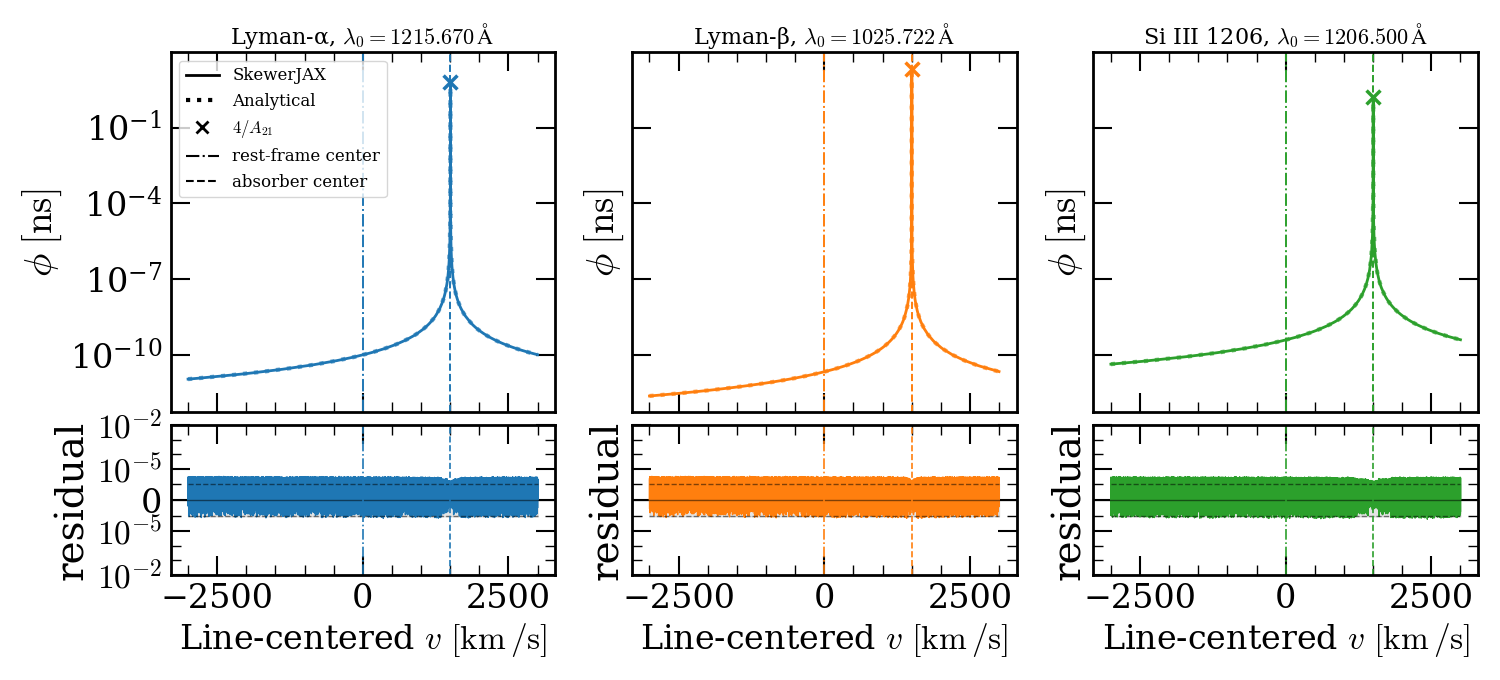

In [10]:
colors = plt.cm.tab10.colors[:line_bundle.n_lines]

N_lines = line_bundle.n_lines
N_v = len(velocities_kms)

phi_plot = phi_ns.reshape(N_lines, -1, N_v)[:, 0, :]
phi_analytic_plot = phi_analytic.reshape(N_lines, -1, N_v)[:, 0, :]

v_center_kms = phys.c_kms * jnp.log(a_dagger / quadri_vectors[0,0])

res_band = 1e-6
res_ticks = [-1e-2, -1e-5, 0.0, 1e-5, 1e-2]
fmt = sjx.utils.plotting_tools.ten_power_formatter

fig_v, axes_v = plt.subplots(2, N_lines, figsize=(5.0 * N_lines, 6.8), sharex="col", sharey="row", gridspec_kw=dict(height_ratios=[2.4, 1.0]))

if N_lines == 1:
    axes_v = axes_v.reshape(2, 1)

for i, line in enumerate(line_bundle.lines):
    ax = axes_v[0, i]
    rx = axes_v[1, i]

    ax.plot(velocities_kms, phi_plot[i], color=colors[i], linewidth=2.0)
    ax.plot(velocities_kms, phi_analytic_plot[i], color=colors[i], linestyle=":", linewidth=3.0, alpha=0.7)

    ax.scatter([v_center_kms], [4.0 / line.A21_GHz], marker="x", color=colors[i], s=100)
    ax.axvline(0.0, color=colors[i], linestyle="-.", linewidth=1.4)
    ax.axvline(v_center_kms, color=colors[i], linestyle="--", linewidth=1.4)

    ax.set_title(rf"{line.name}, $\lambda_0={line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=16)
    ax.set_yscale("log")
    ax.set_ylabel(r"$\phi\;[\mathrm{ns}]$")

    residual = phi_plot[i] / phi_analytic_plot[i] - 1.0

    rx.plot(velocities_kms, residual, color=colors[i], linewidth=1.0)
    rx.axhline(0.0, color="k", linewidth=1.0, alpha=0.5)
    rx.fill_between(velocities_kms, -res_band, res_band, color="grey", alpha=0.2)
    rx.hlines([res_band, -res_band], velocities_kms[0], velocities_kms[-1], color="k", linestyle="--", linewidth=1.0, alpha=0.5)

    rx.axvline(0.0, color=colors[i], linestyle="-.", linewidth=1.2)
    rx.axvline(v_center_kms, color=colors[i], linestyle="--", linewidth=1.2)

    rx.set_xlabel(r"Line-centered $v\ [\mathrm{km\,/s}]$", fontsize=24)
    rx.set_ylabel("residual")
    rx.set_yscale("symlog", linthresh=res_band)
    rx.set_yticks(res_ticks)
    rx.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(fmt))
    rx.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

axes_v[0, 0].legend(
    handles=[
        Line2D([0], [0], color="k", linestyle="-", linewidth=2.0, label="SkewerJAX"),
        Line2D([0], [0], color="k", linestyle=":", linewidth=3.0, label="Analytical"),
        Line2D([0], [0], color="k", marker="x", linestyle="None", markersize=9, markeredgewidth=2, label=r"$4/A_{21}$"),
        Line2D([0], [0], color="k", linestyle="-.", linewidth=1.5, label="rest-frame center"),
        Line2D([0], [0], color="k", linestyle="--", linewidth=1.5, label="absorber center"),
    ],
    fontsize=12, frameon=True,
)

fig_v.tight_layout()
fig_v.subplots_adjust(hspace=0.05, wspace=0.2)
plt.show()

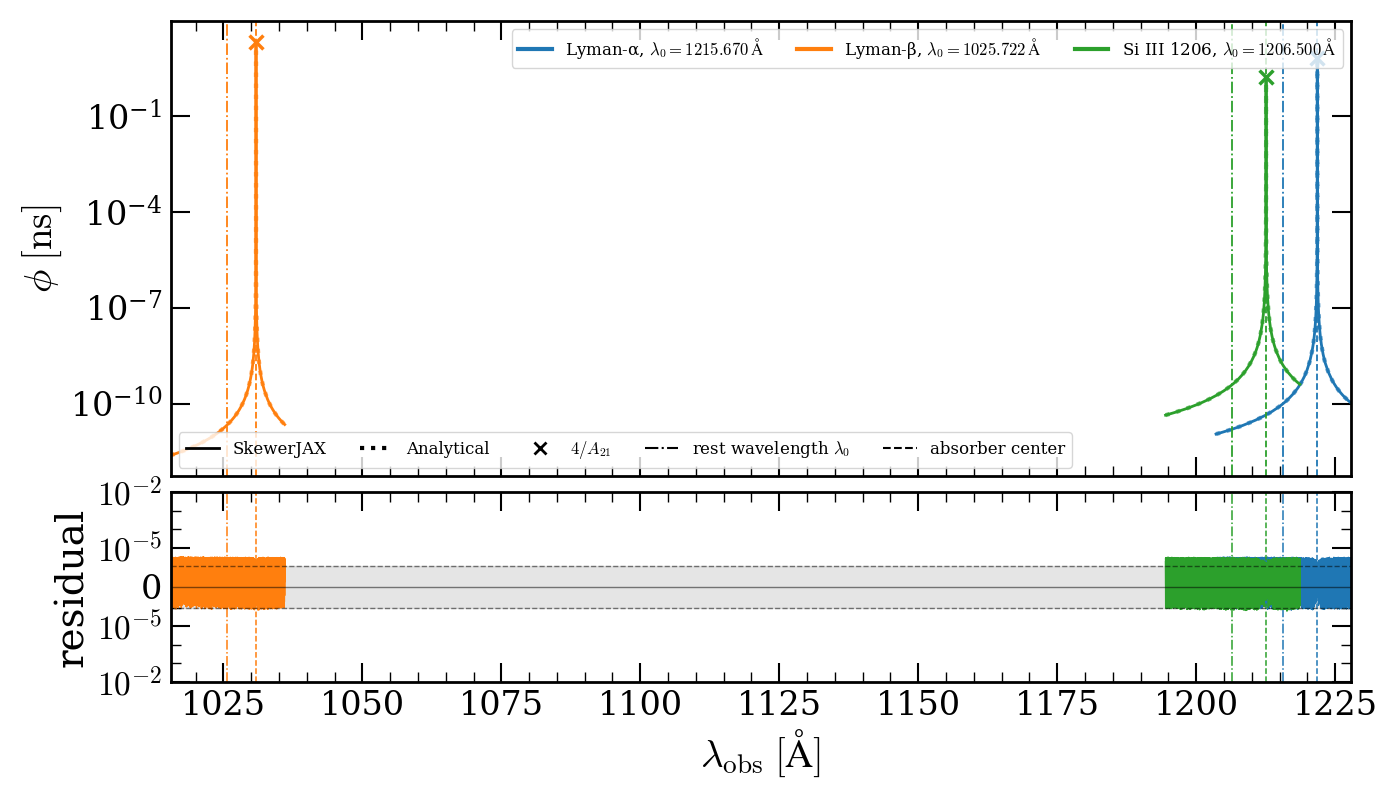

In [11]:
colors = plt.cm.tab10.colors[:line_bundle.n_lines]

N_lines = line_bundle.n_lines
N_v = len(velocities_kms)

phi_plot = phi_ns.reshape(N_lines, -1, N_v)[:, 0, :]
phi_analytic_plot = phi_analytic.reshape(N_lines, -1, N_v)[:, 0, :]

a_obs = 1.0
v_center_kms = phys.c_kms * jnp.log(a_dagger / quadri_vectors[0, 0])

lambda0_A = line_bundle.lambda0_A
lambdas_per_line_A = (lambda0_A[:, None] * (a_obs / a_dagger) * jnp.exp(velocities_kms[None, :] / phys.c_kms))

lambda_center_A = (lambda0_A * (a_obs / a_dagger) * jnp.exp(v_center_kms / phys.c_kms))

x_min = jnp.min(lambdas_per_line_A)
x_max = jnp.max(lambdas_per_line_A)

res_band = 1e-6
res_ticks = [-1e-2, -1e-5, 0.0, 1e-5, 1e-2]
fmt = sjx.utils.plotting_tools.ten_power_formatter

fig_l, (ax_l, rx_l) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(height_ratios=[2.4, 1.0]))

for i, line in enumerate(line_bundle.lines):
    ax_l.plot(lambdas_per_line_A[i], phi_plot[i], color=colors[i], linewidth=2.0)
    ax_l.plot(lambdas_per_line_A[i], phi_analytic_plot[i], color=colors[i], linestyle=":", linewidth=3.0, alpha=0.7)

    ax_l.scatter([lambda_center_A[i]], [4.0 / line.A21_GHz], marker="x", color=colors[i], s=100)
    ax_l.axvline(line.lambda0_A, color=colors[i], linestyle="-.", linewidth=1.3)
    ax_l.axvline(lambda_center_A[i], color=colors[i], linestyle="--", linewidth=1.3)

    residual = phi_plot[i] / phi_analytic_plot[i] - 1.0

    rx_l.plot(lambdas_per_line_A[i], residual, color=colors[i], linewidth=1.0)
    rx_l.axvline(line.lambda0_A, color=colors[i], linestyle="-.", linewidth=1.1)
    rx_l.axvline(lambda_center_A[i], color=colors[i], linestyle="--", linewidth=1.1)

ax_l.set_xlim(x_min, x_max)
ax_l.set_yscale("log")
ax_l.set_ylabel(r"$\phi\;[\mathrm{ns}]$")

rx_l.axhline(0.0, color="k", linewidth=1.0, alpha=0.5)
rx_l.fill_between([x_min, x_max], -res_band, res_band, color="grey", alpha=0.2)
rx_l.hlines([res_band, -res_band], x_min, x_max, color="k", linestyle="--", linewidth=1.0, alpha=0.5)

rx_l.set_xlabel(r"$\lambda_{\rm obs}\;[\mathrm{\AA}]$")
rx_l.set_ylabel("residual")
rx_l.set_yscale("symlog", linthresh=res_band)
rx_l.set_yticks(res_ticks)
rx_l.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(fmt))
rx_l.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

ax_l.legend(
    handles=[
        Line2D([0], [0], color="k", linestyle="-", linewidth=2.0, label="SkewerJAX"),
        Line2D([0], [0], color="k", linestyle=":", linewidth=3.0, label="Analytical"),
        Line2D([0], [0], color="k", marker="x", linestyle="None", markersize=9, markeredgewidth=2, label=r"$4/A_{21}$"),
        Line2D([0], [0], color="k", linestyle="-.", linewidth=1.5, label=r"rest wavelength $\lambda_0$"),
        Line2D([0], [0], color="k", linestyle="--", linewidth=1.5, label="absorber center"),
    ], loc="lower left", fontsize=12, frameon=True, ncols=5,
)

ax_l.add_artist(ax_l.get_legend())

ax_l.legend( handles=[
    Line2D(
        [0], [0], color=colors[i], linewidth=3.0, label=rf"{line.name}, $\lambda_0={line.lambda0_A:.3f}\,\mathrm{{\AA}}$"
        ) for i, line in enumerate(line_bundle.lines)
    ],
    loc="upper right", fontsize=12, frameon=True, ncols=N_lines,
)

fig_l.tight_layout()
fig_l.subplots_adjust(hspace=0.05)
plt.show()

# Check against analytical results varying scale factors

### Define events with different scale factor combinations $(a(x), a_0)$

In [12]:
quadri_vectors = jnp.array([             # quadri-vectors defined at the center of the volume considering different scale factors
    [0.999, L_box/2, L_box/2, L_box/2],
    [0.5,   L_box/2, L_box/2, L_box/2],
    [0.5,   L_box/2, L_box/2, L_box/2],
    [1.0,   L_box/2, L_box/2, L_box/2],
    [1.0,   L_box/2, L_box/2, L_box/2]
])

a_dagger = jnp.array([           # scale factors wrt the observer
    1.0, 0.5, 0.501, 1.003, 0.999
]) 

LoS_directions = jnp.zeros((quadri_vectors.shape[0], 3))
LoS_directions = LoS_directions.at[..., 0].set(1.0)      # line-of-sight directions corresponding to N_sk skewers pointing towards the z-direction, shape (N_sk, N_ppsk, 3)

In [13]:
phi_ns = line_profile.compute_line_profiles(
    quadri_vectors, LoS_directions, velocities_kms, a_dagger, line_bundle, fields, voigt_implementation_mode="ExoJAX",
)

In [14]:
N_lines = line_bundle.n_lines
N_points = quadri_vectors.shape[0]
N_v = velocities_kms.size

lambda0_A = jnp.asarray(line_bundle.lambda0_A)      # (N_lines,)
gamma_GHz = jnp.asarray(line_bundle.A21_GHz) / (4.0 * jnp.pi)

scale_factor = quadri_vectors[:, 0]                 # (N_points,)
LoS_velocity_zero = jnp.zeros((N_lines, N_points))  # (N_lines, N_points)

lambdas_A_prime = line_profile.compute_lambda_prime(
    velocities_kms=velocities_kms,
    lambda0_A=lambda0_A,
    a_dagger=a_dagger,              # (N_points,)
    scale_factor=scale_factor,      # (N_points,)
    LoS_velocity=LoS_velocity_zero, # (N_lines, N_points)
)

# Shape: (N_lines, N_points, N_v)
print("lambdas_A_prime.shape =", lambdas_A_prime.shape)

nu_GHz = (
    (1.0 / lambdas_A_prime)
    - (1.0 / lambda0_A[:, None, None])
) * phys.c * 10.0

gamma_GHz_expanded = gamma_GHz[:, None, None]

phi_analytic = Lorentzian(nu_GHz, gamma_GHz_expanded)

print("phi_analytic.shape =", phi_analytic.shape)
# Expected: (N_lines, N_points, N_v)

lambdas_A_prime.shape = (3, 5, 50000)
phi_analytic.shape = (3, 5, 50000)


/home/dlopez/tmp/pip-tmp/ipykernel_36878/4154699504.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_points])


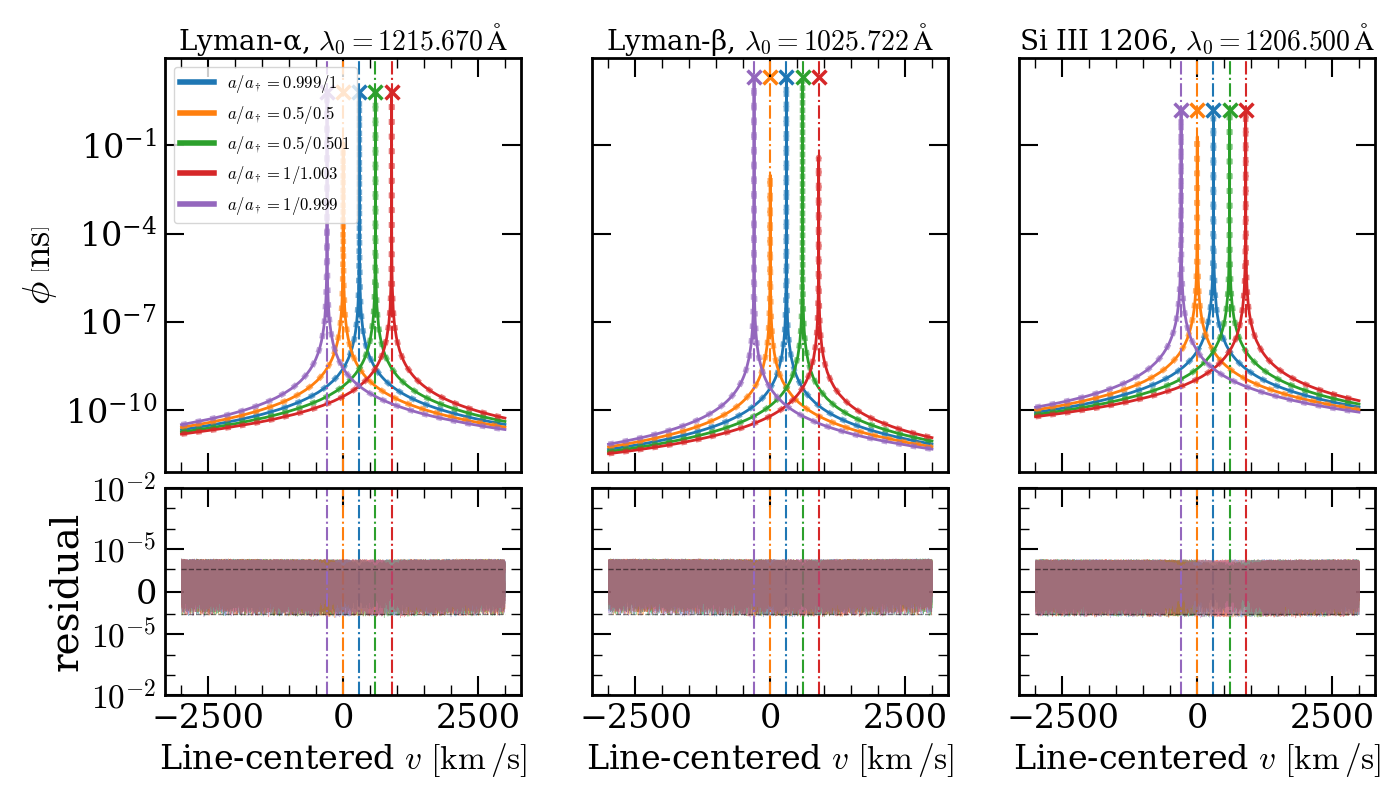

In [15]:
# Convert JAX arrays to NumPy for plotting
velocities_np = np.asarray(velocities_kms)
phi_np = np.asarray(phi_ns)
phi_analytic_np = np.asarray(phi_analytic)

N_lines, N_points = line_bundle.n_lines, quadri_vectors.shape[0]
colors = np.array(plt.cm.get_cmap("tab10").colors[:N_points])
scale_factor = np.asarray(quadri_vectors[:, 0])
a_dagger_np = np.asarray(a_dagger)
a_dagger_per_point = np.full((N_points,), float(a_dagger_np)) if np.ndim(a_dagger_np) == 0 else a_dagger_np

mask = np.ones_like(velocities_np, dtype=bool)
v_win = velocities_np[mask]

fig, axes = plt.subplots(nrows=2, ncols=N_lines, figsize=(14, 8), sharex=True, sharey="row", gridspec_kw=dict(height_ratios=[2, 1]))
if N_lines == 1: axes = axes.reshape(2, 1)

for i_line, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle.lines)):
    for i_point in range(N_points):
        v_peak = phys.c_kms * np.log(a_dagger_per_point[i_point] / scale_factor[i_point])
        peak_height = 4.0 / line_bundle.lines[i_line].A21_GHz

        ax_main.scatter([v_peak], [peak_height], marker="x", color=colors[i_point], s=100, alpha=1.0)
        ax_main.axvline(v_peak, color=colors[i_point], linestyle="-.", linewidth=1.5); ax_res.axvline(v_peak, color=colors[i_point], linestyle="-.", linewidth=1.5)
        ax_main.plot(v_win, phi_np[i_line, i_point, mask], color=colors[i_point], linestyle="-", linewidth=2.0, label="SkewerJAX" if i_point == 0 else None)
        ax_main.plot(v_win, phi_analytic_np[i_line, i_point, mask], color=colors[i_point], linestyle=":", linewidth=4.0, alpha=0.6, label="Analytical" if i_point == 0 else None)

        residual = phi_np[i_line, i_point, mask] / phi_analytic_np[i_line, i_point, mask] - 1.0
        ax_res.plot(v_win, residual, color=colors[i_point], linestyle="-", linewidth=0.5, alpha=0.4)

    ax_res.hlines(1e-6, xmin=v_win[0], xmax=v_win[-1], color="k", linewidth=1, linestyle="--", alpha=0.5)
    ax_res.hlines(-1e-6, xmin=v_win[0], xmax=v_win[-1], color="k", linewidth=1, linestyle="--", alpha=0.5)
    ax_res.set_xlabel(r"Line-centered $v\ [\mathrm{km\,/s}]$", fontsize=24)
    ax_res.set_yscale("symlog", linthresh=1e-6)
    ax_res.set_ylim(-1e-2, 1e-2)
    ax_res.set_yticks([-1e-2, -1e-5, 0.0, 1e-5, 1e-2])
    ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax_main.set_title(rf"{line.name}, $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_yscale("log")

axes[0, 0].set_ylabel(r"$\phi\; \left[\mathrm{ns}\right]$")
axes[1, 0].set_ylabel("residual")

handles = [
    Line2D([0], [0], color=colors[i], lw=4, linestyle="-", label=rf"$a/a_\dagger = {scale_factor[i]:.5g}/{a_dagger_per_point[i]:.5g}$") for i in range(N_points)
]
axes[0, 0].legend(handles=handles, loc="upper left", fontsize=12, ncols=1)

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)
plt.show()

# Check variations with temperature and LoS velocity

### Define the fields to sample

In [16]:
L_box = 1000.0 # UNITS: [Mpc]

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=1e0, T0_max=1e6, L_box=L_box)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=-300.0, v0_max=300.0, L_box=L_box)),  # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                            # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                           # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=1e0, T0_max=1e6, L_box=L_box)), # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=-300.0, v0_max=300.0, L_box=L_box)),  # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                            # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))                           # UNITS: [GHz]
    }
})

### Define wavelength range and lines to study

In [17]:
velocities_kms = jnp.linspace(-400.0, 400.0, 10**4)

In [18]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyB", "SiIII-1206"])

### Define points to evaluate

In [19]:
N_sk = 7
N_ppsk = 5
N_grid = 64

points = aux.make_plane_points(L_box, 'y', L_box/2, N_sk, N_ppsk)  # spatial points corresponding to N_sk skewers of length N_ppsk along the y-plane with y = L_box/2, shape (N_sk, N_ppsk, 3)
scale_factors = jnp.ones(points.shape[0:-1])[..., None]
quadri_vectors = jnp.concatenate([scale_factors, points], axis=-1) # quadri-vectors corresponding to N_sk skewers considering constant scale factors = 1.0, shape (N_sk, N_ppsk, 4)

LoS_directions = jnp.zeros_like(points)
LoS_directions = LoS_directions.at[..., 0].set(1.0)                # line-of-sight directions corresponding to N_sk skewers pointing towards the x-direction, shape (N_sk, N_ppsk, 3)

In [20]:
a_dagger = jnp.ones_like(quadri_vectors[..., 0])

### Compute line profiles

In [21]:
phi_ns = line_profile.compute_line_profiles(
    quadri_vectors, LoS_directions, velocities_kms, a_dagger, line_bundle, fields, voigt_implementation_mode="ExoJAX"
)

### Plot showing temperature variations

In [22]:
scale_factor_obs = np.ones_like(quadri_vectors[..., 0])

linestyles = ['-', '--', ':']

# Convert JAX arrays to NumPy for plotting
phi_np = np.asarray(phi_ns)  # (N_lines, N_sk, N_ppsk, N_v)

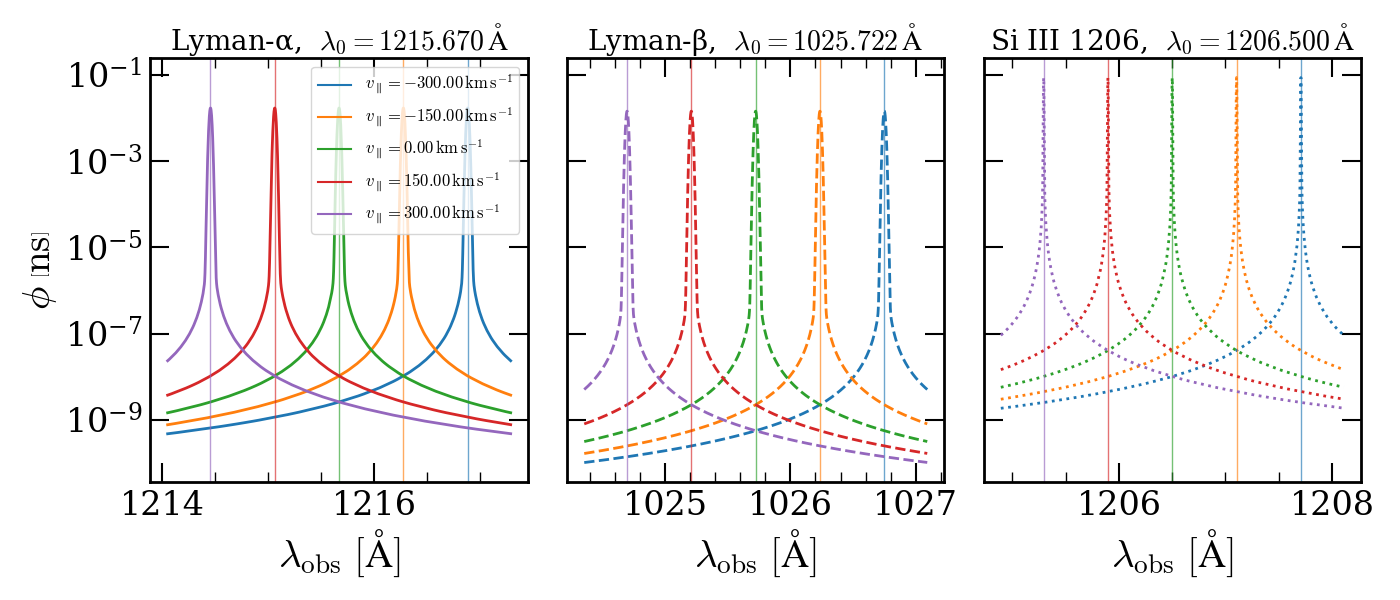

In [23]:
N_ppsk = quadri_vectors.shape[1]
N_v = len(velocities_kms)

# Choose skewer index
i_sk = N_sk // 2

# Pick a_dagger and a_obs once for this selected skewer. This assumes they are scalar or constant along the selected skewer.
if jnp.asarray(a_dagger).ndim == 0:
    a_dagger_plot = a_dagger
else:
    a_dagger_plot = a_dagger[i_sk, 0]

if jnp.asarray(scale_factor_obs).ndim == 0:
    a_obs_plot = scale_factor_obs
else:
    a_obs_plot = scale_factor_obs[i_sk, 0]

wavelengths_per_line_A = line_profile.velocities_to_line_centered_wavelengths(
    velocities_kms, line_bundle, a_dagger_plot, a_obs=a_obs_plot
)  # (N_lines, N_v)

indices_for_species = {sp: line_bundle.indices_for_species(sp) for sp in line_bundle.species_keys}
LoS_velocity_lines = fields.tile_field_to_lines(
    "LoS_velocity", quadri_vectors.reshape(-1, 4), indices_for_species=indices_for_species, LoS_directions=LoS_directions.reshape(-1, 3),
).reshape(line_bundle.n_lines, *quadri_vectors.shape[:-1])



fig, axes = plt.subplots(nrows=1, ncols=line_bundle.n_lines, figsize=(14, 6), sharex=False, sharey=True)
if line_bundle.n_lines == 1:
    axes = [axes]

for i_sp, (ax, line) in enumerate(zip(axes, line_bundle.lines)):
    lambda0 = line.lambda0_A
    lambdas_A = np.asarray(wavelengths_per_line_A[i_sp])

    for i_ppsk in range(N_ppsk):

        a_local = quadri_vectors[i_sk, i_ppsk, 0]
        v_los = LoS_velocity_lines[i_sp, i_sk, i_ppsk]  # [km/s]
        beta = v_los / phys.c_kms
        Dop = jnp.sqrt((1.0 - beta) / (1.0 + beta))
        _lambda_shifted_doppler = float(lambda0 * a_obs_plot / a_local * Dop)
        ax.axvline(_lambda_shifted_doppler, color=colors[i_ppsk], linestyle="-", linewidth=1.0, alpha=0.65)

        profile = phi_np[i_sp, i_sk, i_ppsk, :]

        ax.plot(lambdas_A, profile, color=colors[i_ppsk], linestyle=linestyles[i_sp], linewidth=2.0)

    ax.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax.set_yscale("log")
    ax.set_xlabel(r"$\lambda_{\rm obs}\ [\mathrm{\AA}]$")

axes[0].set_ylabel(r"$\phi\; \left[\mathrm{ns}\right]$")

handles = [Line2D([0], [0], color=colors[i_ppsk], linestyle="-", linewidth=1.5, label=rf"$v_\parallel={float(LoS_velocity_lines[i_sp, i_sk, i_ppsk]):.2f}\,\mathrm{{km\,s^{{-1}}}}$") for i_ppsk in range(N_ppsk)]
axes[0].legend(handles=handles, loc="upper right", fontsize=12, frameon=True)

fig.tight_layout()
plt.show()

/home/dlopez/tmp/pip-tmp/ipykernel_36878/2748482388.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


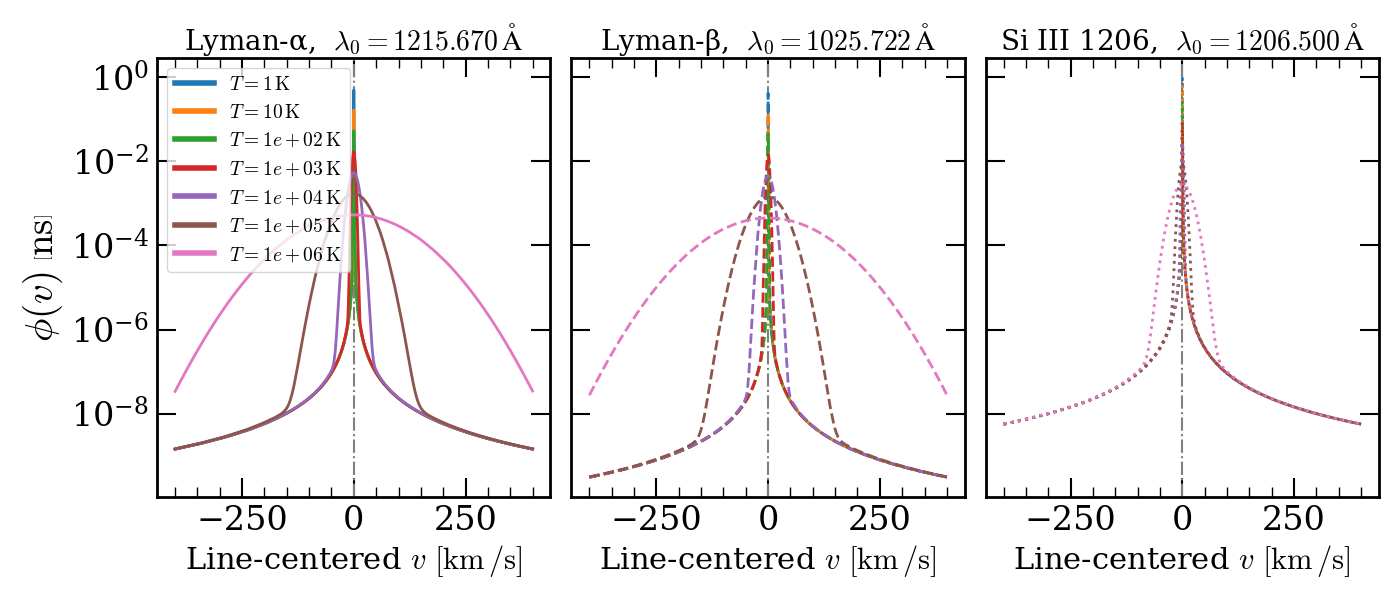

In [24]:
i_ppsk = N_ppsk // 2

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

velocities_np = np.asarray(velocities_kms)

fig, axes = plt.subplots(nrows=1, ncols=line_bundle.n_lines, figsize=(14, 6), sharex=False, sharey=True)
if line_bundle.n_lines == 1:
    axes = [axes]

for i_sp, (ax, line) in enumerate(zip(axes, line_bundle.lines)):
    ax.axvline(0.0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        ax.plot(velocities_np, phi_np[i_sp, i_sk, i_ppsk, :], color=colors[i_sk], linestyle=linestyles[i_sp % len(linestyles)], linewidth=2.0)

    ax.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax.set_yscale("log")
    ax.set_xlabel(r"Line-centered $v\ [\mathrm{km\,/s}]$", fontsize=22)

axes[0].set_ylabel(r"$\phi(v)\; \left[\mathrm{ns}\right]$")

temp_handles = []
for i_sk in range(N_sk):
    _sampled_T = fields.temperature(quadri_vectors[i_sk])
    lbl = rf"$T = {_sampled_T[0, 0]:.2g}\,\mathrm{{K}}$"
    temp_handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=lbl))

axes[0].legend(handles=temp_handles, loc="upper left", fontsize=14, ncols=1, frameon=True)

fig.tight_layout()
plt.show()